## Introducción



In [1]:
import sys
import os

sys.path.append(os.path.abspath("../src"))

import pandas as pd
import matplotlib.pyplot as plt
import unicodedata
import numpy as np
from scipy.stats import spearmanr
import openpyxl
from data_processing import *
from montecarlo import*
from sensitivity import*

In [2]:
if __name__ == "__main__":
    FILE_ACTIVITY = "C:/Users/Pame/Desktop/carbon_uncertainty/data/data_activity.xlsx"
    FILE_UNCERTAINTY = "C:/Users/Pame/Desktop/carbon_uncertainty/data/uncertainty_dist_act_FE.xlsx"
    SEED=12345
    N_ITER = 200000
    
    df, sin_match, discrepancias = construir_dataframe(
    FILE_ACTIVITY,
    FILE_UNCERTAINTY
)

df = afinar_fe_group(df)

df["emision_central_kg"] = (
    df["fe_central"].fillna(0) * df["cantidad"].fillna(0)
)

df["emision_central_tn"] = df["emision_central_kg"] / 1000

afinar_fe_group: se fusionaron 2 conjuntos de fe_group que compartían el mismo valor numérico de FE bajo nombres distintos:
  -> 'guantes de trabajo'  (fusiona: ['guantes de trabajo', 'ropa de trabajo (conjunto)'])
  -> 'productos de limpieza'  (fusiona: ['productos de limpieza', 'resmas de papel a4'])


In [3]:
N_ITER = 200_000
SEED = 12345

# Monte Carlo con FE independientes
rng_naive = np.random.default_rng(SEED)

emis_naive = simular_montecarlo(
    df,
    N_ITER,
    rng_naive,
    correlacionar_fe=False
)

# Monte Carlo con FE correlacionados
rng_corr = np.random.default_rng(SEED)

emis_corr = simular_montecarlo(
    df,
    N_ITER,
    rng_corr,
    correlacionar_fe=True
)

In [4]:
# Emisiones centrales por actividad
# Las cantidades simuladas y los factores de emisión
# se expresan de modo que el producto resulte en kg CO2e.
df = df.copy()

df["emision_central_kg"] = (
    df["cantidad"].fillna(0) * df["fe_central"].fillna(0)
)

df["emision_central_tn"] = df["emision_central_kg"] / 1000

# Para asegurar que la posición de cada fila coincida
# con la columna correspondiente de las matrices:
df = df.reset_index(drop=True)

assert emis_naive.shape[1] == len(df)
assert emis_corr.shape[1] == len(df)

3. Composición del inventario: emisiones por fuente
El objetivo es identificar qué actividades explican la mayor parte de las emisiones centrales del inventario.
Para que el gráfico sea legible en la presentación, mostraría las 10 actividades con mayores emisiones y agruparía el resto como “Otras actividades”.

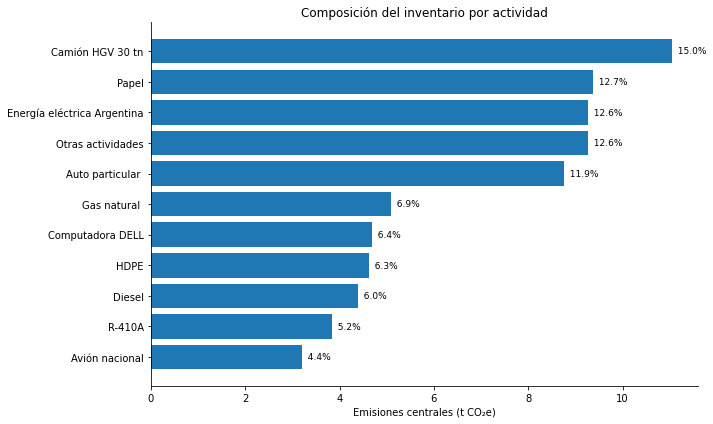

In [13]:
# Agregar emisiones por actividad
emisiones_actividad = (
    df.groupby("actividad", as_index=False)["emision_central_tn"]
      .sum()
      .sort_values("emision_central_tn", ascending=False)
)

total_emisiones = emisiones_actividad["emision_central_tn"].sum()

emisiones_actividad["porcentaje"] = (
    emisiones_actividad["emision_central_tn"] / total_emisiones * 100
)

# Top 10 + otras actividades
top_n = 10

top = emisiones_actividad.head(top_n).copy()

if len(emisiones_actividad) > top_n:
    otras = pd.DataFrame({
        "actividad": ["Otras actividades"],
        "emision_central_tn": [
            emisiones_actividad.iloc[top_n:]["emision_central_tn"].sum()
        ],
    })
    otras["porcentaje"] = (
        otras["emision_central_tn"] / total_emisiones * 100
    )
    top = pd.concat([top, otras], ignore_index=True)

# Orden para el gráfico horizontal
top = top.sort_values("emision_central_tn")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top["actividad"],
    top["emision_central_tn"]
)

ax.set_xlabel("Emisiones centrales (t CO₂e)")
ax.set_ylabel("")
ax.set_title("Composición del inventario por actividad")

for bar, pct in zip(bars, top["porcentaje"]):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {pct:.1f}%",
        va="center",
        fontsize=9
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

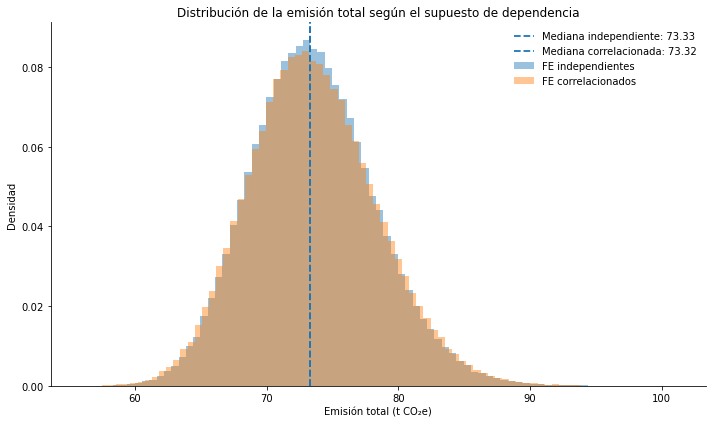

In [12]:
# Emisión total por iteración, en toneladas
total_naive = emis_naive.sum(axis=1) / 1000
total_corr = emis_corr.sum(axis=1) / 1000

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    total_naive,
    bins=80,
    density=True,
    alpha=0.45,
    label="FE independientes"
)

ax.hist(
    total_corr,
    bins=80,
    density=True,
    alpha=0.45,
    label="FE correlacionados"
)

# Medianas
mediana_naive = np.median(total_naive)
mediana_corr = np.median(total_corr)

ax.axvline(
    mediana_naive,
    linestyle="--",
    linewidth=1.8,
    label=f"Mediana independiente: {mediana_naive:.2f}"
)

ax.axvline(
    mediana_corr,
    linestyle="--",
    linewidth=1.8,
    label=f"Mediana correlacionada: {mediana_corr:.2f}"
)

ax.set_xlabel("Emisión total (t CO₂e)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de la emisión total según el supuesto de dependencia")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
amplitud_naive = (
    np.percentile(total_naive, 97.5)
    - np.percentile(total_naive, 2.5)
)

amplitud_corr = (
    np.percentile(total_corr, 97.5)
    - np.percentile(total_corr, 2.5)
)

cambio_pct = (
    (amplitud_corr - amplitud_naive) / amplitud_naive * 100
)

print(f"Amplitud MC independiente: {amplitud_naive:.2f} t CO₂e")
print(f"Amplitud MC correlacionado: {amplitud_corr:.2f} t CO₂e")
print(f"Cambio relativo de amplitud: {cambio_pct:.1f}%")

Amplitud MC independiente: 18.44 t CO₂e
Amplitud MC correlacionado: 18.89 t CO₂e
Cambio relativo de amplitud: 2.4%


In [8]:
tabla_sens = sensibilidad(df, emis_corr)

display(
    tabla_sens[
        [
            "actividad",
            "emision_media_pct_total",
            "contribucion_incertidumbre_pct",
            "indice_riesgo",
        ]
    ].head(10).round(2)
)

,actividad,emision_media_pct_total,contribucion_incertidumbre_pct,indice_riesgo
30,Camión HGV 30 tn,15.01,33.25,2.22
17,Papel,12.73,18.98,1.49
41,Auto particular,9.42,15.15,1.61
22,Computadora DELL,6.36,8.51,1.34
18,HDPE,6.30,4.62,0.73
39,Auto particular,2.48,3.07,1.24
37,RSU,2.59,2.89,1.11
4,R-410A,5.23,2.78,0.53
38,Avión nacional,4.36,2.76,0.63
5,Energía eléctrica Argentina,9.04,2.65,0.29


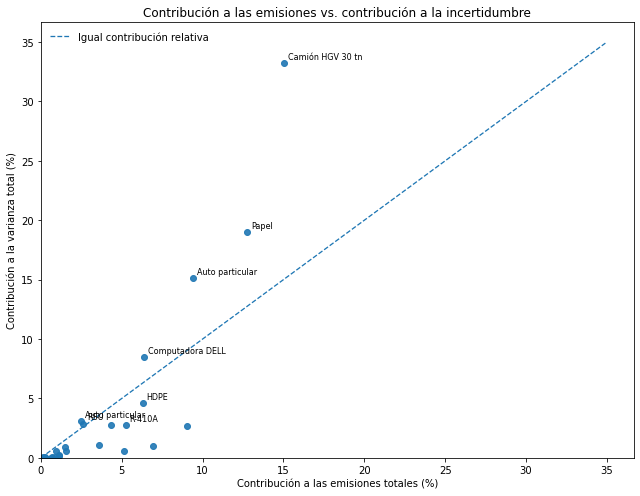

In [19]:
fig, ax = plt.subplots(figsize=(9, 7))

x = tabla_sens["emision_media_pct_total"]
y = tabla_sens["contribucion_incertidumbre_pct"]

ax.scatter(x, y, alpha=0.9)

# Diagonal de igualdad
limite = max(
    x.max(),
    y.max(),
    1
) * 1.05

ax.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    linewidth=1.3,
    label="Igual contribución relativa"
)

# Etiquetar las actividades con mayor contribución
# a la incertidumbre
top_etiquetas = tabla_sens.nlargest(
    8, "contribucion_incertidumbre_pct"
)

for _, row in top_etiquetas.iterrows():
    ax.annotate(
        str(row["actividad"]),
        (
            row["emision_media_pct_total"],
            row["contribucion_incertidumbre_pct"],
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.set_xlabel("Contribución a las emisiones totales (%)")
ax.set_ylabel("Contribución a la varianza total (%)")
ax.set_title("Contribución a las emisiones vs. contribución a la incertidumbre")
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [15]:
resultados_alcance = []

for alcance in sorted(df["alcance"].dropna().unique()):
    mask = df["alcance"].eq(alcance).to_numpy()

    # Emisión total de este alcance en cada iteración
    emisiones = emis_corr[:, mask].sum(axis=1) / 1000

    media = np.mean(emisiones)
    sd = np.std(emisiones, ddof=1)

    p2_5, p50, p97_5 = np.percentile(
        emisiones, [2.5, 50, 97.5]
    )

    resultados_alcance.append({
        "alcance": f"Alcance {alcance}",
        "media_tn": media,
        "sd_tn": sd,
        "cv_pct": sd / media * 100 if media != 0 else np.nan,
        "p2_5": p2_5,
        "mediana": p50,
        "p97_5": p97_5,
        "amplitud_ic95": p97_5 - p2_5,
    })

tabla_alcances = pd.DataFrame(resultados_alcance)

tabla_alcances["emision_pct_total"] = (
    tabla_alcances["media_tn"]
    / tabla_alcances["media_tn"].sum()
    * 100
)

display(tabla_alcances.round(3))

,alcance,media_tn,sd_tn,cv_pct,p2_5,mediana,p97_5,amplitud_ic95,emision_pct_total
0,Alcance 1,13.786,1.012,7.341,11.957,13.731,15.930,3.972,18.744
1,Alcance 2,9.272,0.931,10.041,7.447,9.271,11.094,3.647,12.606
2,Alcance 3,50.493,4.634,9.179,42.096,50.252,60.252,18.156,68.650


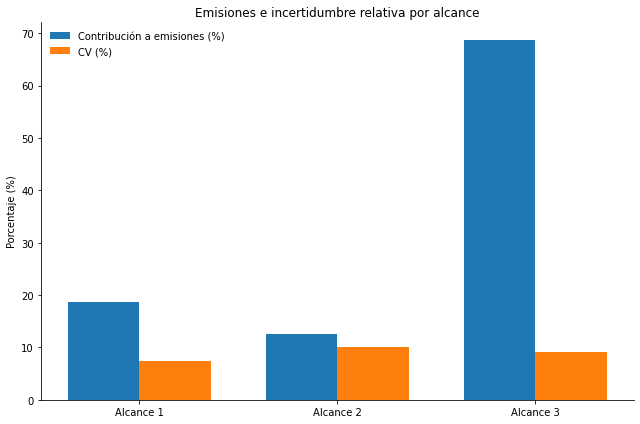

In [18]:
fig, ax = plt.subplots(figsize=(9, 6))

posiciones = np.arange(len(tabla_alcances))
ancho = 0.36

ax.bar(
    posiciones - ancho / 2,
    tabla_alcances["emision_pct_total"],
    width=ancho,
    label="Contribución a emisiones (%)",
)

ax.bar(
    posiciones + ancho / 2,
    tabla_alcances["cv_pct"],
    width=ancho,
    label="CV (%)",
)

ax.set_xticks(posiciones)
ax.set_xticklabels(tabla_alcances["alcance"])
ax.set_ylabel("Porcentaje (%)")
ax.set_title("Emisiones e incertidumbre relativa por alcance")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

In [2]:
# ------------------------------------------------------------------------------
# 1. AJUSTE Y MUESTREO DE DISTRIBUCIONES
# ------------------------------------------------------------------------------


In [4]:
# ------------------------------------------------------------------------------
# 3. SIMULACIÓN MONTE CARLO (Approach 2, IPCC) -- ingenuo vs. correlacionado
# ------------------------------------------------------------------------------


In [5]:
# ------------------------------------------------------------------------------
# 4. RESUMEN
# ------------------------------------------------------------------------------




In [6]:
# ------------------------------------------------------------------------------
# 5. ANÁLISIS DE SENSIBILIDAD -- contribución a la INCERTIDUMBRE, no a la emisión
# ------------------------------------------------------------------------------



0 valores de FE que aparecen bajo MÁS DE UN fe_group distinto (correlación perdida):


fe_group
utilitario 3.5 tn              4
diesel                         2
reciclables                    2
productos de limpieza          2
energia electrica argentina    2
guantes de trabajo             2
auto particular                2
carton                         1
moto                           1
toner para impresora           1
dtype: int64


                   fe_group  n_actividades                 actividades  emision_media_tn  contribucion_incertidumbre_pct
           camion hgv 30 tn              1            Camión HGV 30 tn         11.036788                       33.247611
                      papel              1                       Papel          9.365641                       18.977655
            auto particular              2            Auto particular           8.756426                       18.221999
           computadora dell              1            Computadora DELL          4.678811                        8.505228
                       hdpe              1                        HDPE          4.630728                        4.623014
energia electrica argentina              2 Energía eléctrica Argentina          9.272020                        3.699216
                        rsu              1                         RSU          1.908248                        2.886965
                     r-410a     